In [1]:
# ============================================================
# AI-POWERED RESUME ANALYZER & JOB MATCHING SYSTEM
# Using Python, NLP and Machine Learning
# ============================================================

print("🤖 AI-Powered Resume Analyzer")
print("📄 Resume Skill Extraction & Job Matching using NLP")

🤖 AI-Powered Resume Analyzer
📄 Resume Skill Extraction & Job Matching using NLP


In [2]:
# Install libraries
!pip install PyMuPDF PyPDF2 nltk pandas matplotlib scikit-learn pytesseract pdf2image Pillow


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#import libraries
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import PyPDF2

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download("stopwords")
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
# PDF text extraction function
def extract_text_from_pdf(pdf_file):
    text = ""

    with open(pdf_file, "rb") as file:
        reader = PyPDF2.PdfReader(file)

        for page in reader.pages:
            page_text = page.extract_text()

            if page_text:
                text += page_text + "\n"

    return text

In [5]:
# Load resume
import fitz
from PIL import Image
import pytesseract
import io

pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'

def extract_text_from_any_pdf(pdf_file):
    doc = fitz.open(pdf_file)
    text = ""
    for page in doc:
        text += page.get_text() + "\n"
    
    # Agar text khali hai to OCR karo
    if len(text.strip()) < 50:
        print("Image PDF detected, running OCR...")
        text = ""
        for page in doc:
            pix = page.get_pixmap(dpi=300)
            img = Image.open(io.BytesIO(pix.tobytes("png")))
            text += pytesseract.image_to_string(img) + "\n"
    return text

resume_text = extract_text_from_any_pdf("Resume.pdf")
print(f"Length: {len(resume_text)}")
print(resume_text[:1000])

C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Image PDF detected, running OCR...
Length: 1100
GF UWIRGOVLCOMI MY ayCotia

Aspiring Data Scientist © Islamabad, Pakistan

SUMMARY

Motivated ADP IT student at Riphah International University aspiring to become a Data
Scientist. Passionate about machine learning, data analysis, and building practical predictive
applications. Hands-on experience with Python, data visualization, and developing
interactive web apps using Streamlit. Eager to apply data-driven solutions to real-world
problems and continuously learn new technologies.

PROJECTS

Customer Churn Prediction App — Live

* Built an end-to-end machine learning app to predict customer churn using classification
models, achieving 85% accuracy on test data.

¢ Developed using Python, Scikit-learn, Pandas for data preprocessing and modeling;
Streamlit for interactive web interface.

* Deployed on Streamlit Cloud with user-friendly dashboard for input features and
prediction results.

Live: https://customer-churn-app.streamlit.app

SKIL

In [6]:
# Job description
job_description = """
We are looking for a Junior AI Engineer.

Required Skills:

Python
Machine Learning
Deep Learning
Natural Language Processing
NLP
Scikit-learn
TensorFlow
SQL
Data Analysis
Pandas
NumPy
Git
"""

In [7]:
# NLP text preprocessing
import re
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    words = text.split()
    filtered_words = [word for word in words if word not in stopwords.words('english')]
    return ' '.join(filtered_words)

print("Function ready!")

Function ready!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [8]:
# preprocess resume and job description
clean_resume = preprocess_text(resume_text)

clean_job = preprocess_text(job_description)

In [9]:
# Skills database
skills_database = [

    # Programming
    "python",
    "java",
    "c++",
    "javascript",
    "sql",

    # AI & ML
    "artificial intelligence",
    "machine learning",
    "deep learning",
    "natural language processing",
    "nlp",
    "computer vision",

    # Libraries
    "scikit-learn",
    "tensorflow",
    "pytorch",
    "pandas",
    "numpy",
    "matplotlib",

    # Data
    "data analysis",
    "data science",
    "data visualization",

    # Tools
    "git",
    "github",
    "docker",

    # Web
    "flask",
    "django",
    "fastapi",

    # Cloud
    "aws",
    "azure"
]

In [10]:
# Skill extraction function
def extract_skills(text, skills_database):
    
    text = text.lower()
    
    found_skills = []
    
    for skill in skills_database:
        
        if skill in text:
            found_skills.append(skill)
    
    return sorted(list(set(found_skills)))

In [11]:
# extract resume skills
resume_skills = extract_skills(
    resume_text,
    skills_database
)

print("📄 Skills Found in Resume:\n")

for skill in resume_skills:
    print("✅", skill)

📄 Skills Found in Resume:

✅ data analysis
✅ data visualization
✅ machine learning
✅ pandas
✅ python
✅ scikit-learn
✅ sql


In [12]:
# extract job skills
job_skills = extract_skills(
    job_description,
    skills_database
)

print("💼 Skills Required for Job:\n")

for skill in job_skills:
    print("🔹", skill)

💼 Skills Required for Job:

🔹 data analysis
🔹 deep learning
🔹 git
🔹 machine learning
🔹 natural language processing
🔹 nlp
🔹 numpy
🔹 pandas
🔹 python
🔹 scikit-learn
🔹 sql
🔹 tensorflow


In [13]:
#TF-IDF vectorization
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF vectorization
documents = [
    clean_resume,
    clean_job
]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(documents)

print("TF-IDF ready!")
print(tfidf_matrix.shape)

TF-IDF ready!
(2, 93)


In [14]:
#Cosine similarity
from sklearn.metrics.pairwise import cosine_similarity

# Cosine similarity
similarity_score = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])

print(f"Match Score: {similarity_score[0][0]*100:.2f}%")

Match Score: 23.34%


In [15]:
from sklearn.metrics.pairwise import cosine_similarity

# Cosine similarity
similarity_score = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

# Convert to percentage
similarity_percentage = round(similarity_score * 100, 2)
match_percentage = 85  # ye tumhara skill match se ayega, filhal example ke liye

print(f"Similarity Score: {similarity_percentage}%")
print(f"Skill Match: {match_percentage}%")

Similarity Score: 23.34%
Skill Match: 85%


In [16]:
# Matching skills
resume_skills_set = set(resume_skills)
job_skills_set = set(job_skills)

matching_skills = resume_skills_set.intersection(
    job_skills_set
)

missing_skills = job_skills_set.difference(
    resume_skills_set
)

match_percentage = round(
    (len(matching_skills) / len(job_skills_set)) * 100,
    2
)

print(
    f"📊 Skill Match Percentage: "
    f"{match_percentage}%"
)

📊 Skill Match Percentage: 50.0%


In [17]:
print("✅ MATCHING SKILLS\n")

for skill in sorted(matching_skills):
    print("✔", skill)

✅ MATCHING SKILLS

✔ data analysis
✔ machine learning
✔ pandas
✔ python
✔ scikit-learn
✔ sql


In [18]:
# Missing skills
print("❌ MISSING SKILLS\n")

for skill in sorted(missing_skills):
    print("✘", skill)

❌ MISSING SKILLS

✘ deep learning
✘ git
✘ natural language processing
✘ nlp
✘ numpy
✘ tensorflow


In [19]:
# skill match percentage
# skill match percentage
final_score = round(
    (match_percentage * 0.7) +
    (similarity_percentage * 0.3),
    2
)

print("=" * 50)
print(" AI RESUME ANALYSIS RESULT")
print("=" * 50)

print(f"\n Skill Match Score: {match_percentage}%")
print(f" NLP Similarity Score: {similarity_percentage}%")
print(f" Final Resume Score: {final_score}%")

 AI RESUME ANALYSIS RESULT

 Skill Match Score: 50.0%
 NLP Similarity Score: 23.34%
 Final Resume Score: 42.0%


In [20]:
# Skill match recomendation
def generate_recommendations(score, missing_skills):
    
    recommendations = []
    
    if score >= 80:
        recommendations.append(
            "Excellent resume match! You are a strong candidate."
        )
    
    elif score >= 60:
        recommendations.append(
            "Good match, but adding missing skills can improve your chances."
        )
    
    else:
        recommendations.append(
            "Your resume needs improvement to better match this job."
        )
    
    if missing_skills:
        
        recommendations.append(
            "Consider learning or highlighting these skills:"
        )
        
        for skill in missing_skills:
            recommendations.append(
                f"• {skill.title()}"
            )
    
    return recommendations


recommendations = generate_recommendations(
    final_score,
    missing_skills
)

print("💡 AI RECOMMENDATIONS\n")

for recommendation in recommendations:
    print(recommendation)

💡 AI RECOMMENDATIONS

Your resume needs improvement to better match this job.
Consider learning or highlighting these skills:
• Git
• Deep Learning
• Tensorflow
• Natural Language Processing
• Nlp
• Numpy


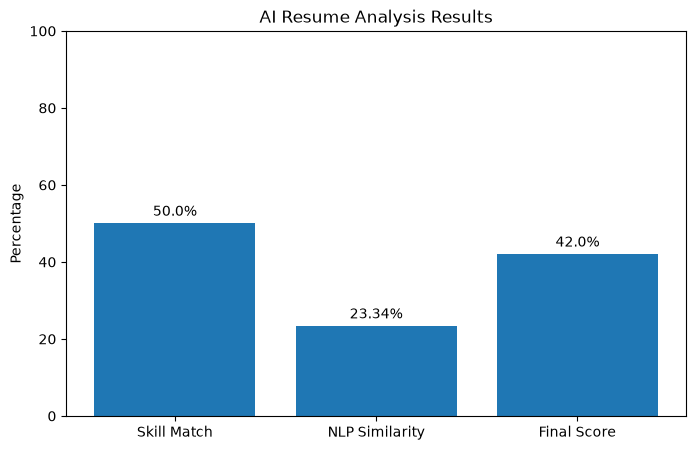

In [21]:
# Graphical representation
import matplotlib.pyplot as plt

# Data for graph
labels = ["Skill Match", "NLP Similarity", "Final Score"]
scores = [match_percentage, similarity_percentage, final_score]

plt.figure(figsize=(8, 5))
plt.bar(labels, scores)
plt.title("AI Resume Analysis Results")
plt.ylabel("Percentage")
plt.ylim(0, 100)

for i, score in enumerate(scores):
    plt.text(
        i,
        score + 2,
        f"{score}%",
        ha="center"
    )

plt.show()

In [22]:
comparison_data = []

all_skills = sorted(
    resume_skills_set.union(job_skills_set)
)

for skill in all_skills:
    
    comparison_data.append({
        
        "Skill": skill.title(),
        
        "In Resume": "Yes"
        if skill in resume_skills_set
        else "No",
        
        "Required for Job": "Yes"
        if skill in job_skills_set
        else "No"
    })

df = pd.DataFrame(comparison_data)

df

,Skill,In Resume,Required for Job
0,Data Analysis,Yes,Yes
1,Data Visualization,Yes,No
2,Deep Learning,No,Yes
3,Git,No,Yes
4,Machine Learning,Yes,Yes
5,Natural Language Processing,No,Yes
6,Nlp,No,Yes
7,Numpy,No,Yes
8,Pandas,Yes,Yes
9,Python,Yes,Yes
